In [1]:
import sys
import os
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import torch
import random
import torch.nn.functional as F
import networkx as nx

In [2]:
np.random.seed(0)
torch.manual_seed(0)
random.seed(0)

In [3]:
def read_parameters(file_path):
    params = {}

    # First pass: read and store values as strings
    with open(file_path, 'r') as file:
        for line in file:
            # Skip empty lines and comments (if any)
            line = line.strip()
            if line and not line.startswith('#'):
                # Split the line at the equals sign
                key, value = line.split('=')
                key = key.strip()
                value = value.strip()

                # Store the parameter as a string for now
                params[key] = value

    # Second pass: evaluate expressions and convert values
    for key, value in params.items():
        try:
            # Try to evaluate the value as a Python expression using previously defined parameters
            params[key] = eval(value, {}, params)
        except:
            # If it's not an expression, check if it can be converted to float or int
            if '.' in value:
                params[key] = float(value)
            else:
                params[key] = int(value)
        
        # Set the variable in the global namespace with the evaluated value
        globals()[key] = params[key]

    return params

In [4]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move import *
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/phd/pytorch_DGN/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [5]:
work_folder = 'edge_spen'
saving_folder = 'l0'
os.chdir(work_folder)

In [6]:
file_path = saving_folder + '/parameters.txt'  # Path to the parameters file
parameters = read_parameters(file_path)

for key, value in parameters.items():
    print(f"{key} = {value}")

n = 300
Lx = 32
Ly = 32
delta = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]
eta = 0.01
decay_rate = 0.015
eta_special = 1
n_special = 30
t_transient = 200
tmax = 1200
batch_size = 60
gamma = 0.99
state_dim = (4, 9, 9)
action_dim = 8
action_bound = 1
vision = 9
actor_lr = 5e-06
critic_lr = 5e-05
weight_decay = 0.0
clip_epsilon = 0.2
entropy_coeff = 0.05
policy_steps = 1000
learning_steps = 1
clip_grad = False
use_gae = True
lam = 0.95


In [7]:
eta = 0.01
decay_rate = 0.015
eta_special = 1
n_special = 30
n = 300

In [8]:
def beta_crit(d, s0):
    return 1 + 1/s0 + 2*d + d*s0 + d**2*s0

s0_prime = (n*eta + n_special*eta_special)/(decay_rate*Lx**2)
s0 = (n*eta)/(decay_rate*Lx**2) 
print(s0)

0.1953125


In [9]:
vision=state_dim[-1]
from ppo_ants import *

In [10]:
def setup_environment(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                        tmax, n_special, t_transient, vision,
                        gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
                        clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                        state_dim, action_dim, clip_grad, saving_folder):
    
    env = Ants(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
            tmax, n_special, t_transient, vision=state_dim[-1])
    
    sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))

    config_net_file = f"{saving_folder}/networks.yaml"
    ppo_ants = PPO_ants( env,
                    gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay, config_net_file,
                    clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                    state_dim, action_dim, clip_grad)

    return env, ppo_ants

In [11]:
env, ppo_ants = setup_environment(
    n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
    tmax, n_special, t_transient, vision,
    gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
    clip_epsilon, entropy_coeff, policy_steps, learning_steps,
    state_dim, action_dim, clip_grad, saving_folder
)

In [12]:
critic_test = 'weights/critic.pth'
actor_test = 'weights/actor.pth'

In [13]:
def load_policy_weights(ppo_ants, actor_test, critic_test):
    if not os.path.exists(f"{saving_folder}/{critic_test}"):
        print(f"Warning: {critic_test} or {actor_test} not found in {saving_folder}. Using default weights.")
    else:
        ppo_ants.critic.load_state_dict(torch.load(f"{saving_folder}/{critic_test}", weights_only=True))
        ppo_ants.actor.load_state_dict(torch.load(f"{saving_folder}/{actor_test}", weights_only=True))

In [14]:
# withdrawal 

# a t = T rimuovo gli smart/enhanced vedere dopo quanti time step gli abm si perdono, guardando le metriche
# come evolvono e quanto ( e se) decadono. 

# perturbation 

# a t = T metto a 0 celle nella grid distruggendo i trail.
# levare un numero di celle random ad ogni time step e vedere come evolvono le metriche
# levare una intera regione 

In [15]:
import torch.distributions as distributions
def test_forward_pass(self, max_prob=False, save_pos = False, reset=True, withdrawal=False, T=2200):

    saved_pattern = np.zeros_like(self.env.pheromones, dtype=bool)
    states, actions, rewards, done, episode_reward = [], [], [], False, 0.0
    if reset:
        self.env.reset_objects()
    self.env.transient()
    self.actor.eval()
    self.critic.eval()
    
    state = self.get_state().copy()
    state_tensor = torch.FloatTensor(state)

    if save_pos:
        pos = []
        pher = []

    while self.env.t < T:

        # Get action probabilities and value prediction from the agent.
        action_pred = self.actor(state_tensor)
        action_prob = F.softmax(action_pred, dim=-1)
        dist = distributions.Categorical(action_prob)
        action = dist.sample()

        if withdrawal:
            if self.env.t > self.env.tmax:
                '''plt.imshow(self.env.pheromones, cmap='YlGnBu')
                plt.colorbar(label='Pheromone concentration')
                plt.title(f'Pheromone pattern at t={self.env.t}')
                plt.show()'''
                self.env.amount[self.env.n:] = 0
                # print(f"pheromone concetration {self.env.pheromones.mean()} at t={self.env.t}", end="\r")
        
        if max_prob:
            action = np.argmax(action_prob.detach(), axis=1)

        # Store log probability of the selected action.
        new_state, reward, done = self.execute_action(action.detach().numpy())
        
        rewards.append(reward)
        episode_reward += np.mean(reward)
        actions.append(action)
        if save_pos:
            pos.append(self.env.positions.copy())
            pher.append(self.env.pheromones.copy())

        state = new_state.copy() 
        state_tensor = torch.FloatTensor(state)
        states.append(state_tensor)


    # Convert to tensors and calculate advantages (returns - values).
    states = torch.cat(states)

    if save_pos: 
        return episode_reward, states, torch.cat(actions), rewards, pos, pher, saved_pattern

    else:
        return episode_reward, states, torch.cat(actions), rewards

In [ ]:
env, ppo_ants = setup_environment(
    n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
    tmax, n_special, t_transient, vision,
    gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
    clip_epsilon, entropy_coeff, policy_steps, learning_steps,
    state_dim, action_dim, clip_grad, saving_folder
)

ppo_ants.setup_networks()

load_policy_weights(ppo_ants, actor_test, critic_test)

b = 6.5
d = 0.6

ppo_ants.env.reset_objects()
ppo_ants.env.delta[:] = np.ones(n+n_special) * d
ppo_ants.env.beta[:] = np.ones(n+n_special) * b

episode_reward, states, actions, rewards, pos, pher, pattern = test_forward_pass(ppo_ants, max_prob=False, save_pos=True,
                                                                        reset=False, withdrawal=True, T=2200)

TypeError: setup_environment() missing 1 required positional argument: 'saving_folder'

In [17]:
np.array(pher).shape

NameError: name 'pher' is not defined

In [18]:
def order_parameter_s(pheromones, V):
    s0 = np.mean(pheromones)
    plus_id = pheromones > s0
    minus_id = ~plus_id
    
    n_plus = np.sum(plus_id)
    n_minus = np.sum(minus_id)
    
    if n_plus == 0 or n_minus == 0:
        return 0.0
    
    s_plus_avg = np.mean(pheromones[plus_id])
    s_minus_avg = np.mean(pheromones[minus_id])
    
    return ((s_plus_avg - s_minus_avg) / (s0 * V)) * n_plus


def order_parameter_p(pheromones, rho):
    s0 = np.mean(pheromones)
    plus_id = pheromones > s0
    minus_id = ~plus_id
    
    n_plus = np.sum(plus_id)
    n_minus = np.sum(minus_id)
    
    if n_plus == 0 or n_minus == 0:
        return 0.0
    
    mu_plus = np.mean(rho[plus_id])
    mu_minus = np.mean(rho[minus_id])
    
    denom = mu_plus + mu_minus
    if denom == 0:
        return 0.0
        
    return (mu_plus - mu_minus) / denom

In [19]:
order_param_s = []
order_param_p = []

def compute_density(positions, Lx, Ly, n):

    rho = np.bincount(np.array(positions[:n,0]*Ly + positions[:n,1]), minlength=Lx*Ly)
    rho = rho.reshape(Lx, Ly)

    return rho

rhos = [compute_density(pos[i], Lx, Ly, n) for i in range(len(pos))]

for pheromones, rho in zip(pher, rhos):
    s = order_parameter_s(pheromones, Lx * Ly)
    p = order_parameter_p(pheromones, rho)
    order_param_s.append(s)
    order_param_p.append(p)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(order_param_s, label='Order Parameter S', color='blue')
plt.title('Order Parameter S over Time')
plt.xlabel('Time Steps')
plt.ylabel('Order Parameter S')
plt.vlines(x=ppo_ants.env.tmax-ppo_ants.env.t_transient,
            color='red', linestyle='--', label='Withdrawal Time', ymin=0, ymax=1)
plt.subplot(1, 2, 2)
plt.plot(order_param_p, label='Order Parameter P', color='orange')
plt.title('Order Parameter P over Time')
plt.xlabel('Time Steps')
plt.ylabel('Order Parameter P')
plt.tight_layout()
plt.vlines(x=ppo_ants.env.tmax-ppo_ants.env.t_transient,
            color='red', linestyle='--', label='Withdrawal Time', ymin=-1, ymax=1)
plt.show()

NameError: name 'pos' is not defined

In [20]:
plt.plot(np.mean(pher, axis=(1,2)), label='Average Pheromone Concentration', color='green')
plt.title('Average Pheromone Concentration over Time')
plt.xlabel('Time Steps')
plt.ylabel('Average Pheromone Concentration')
plt.vlines(x=ppo_ants.env.tmax-ppo_ants.env.t_transient,
            color='red', linestyle='--', label='Withdrawal Time', ymin=0, ymax=np.mean(pher, axis=(1,2)).max())
plt.legend()
plt.show()

NameError: name 'pher' is not defined

In [21]:
plt.imshow(np.array(pher)[env.tmax], cmap='YlGnBu')
plt.colorbar(label='Pheromone concentration')
plt.scatter(np.array(pos)[env.tmax][:n, 1], np.array(pos)[env.tmax][:n, 0], c='red', s=10, label='Ant Positions')
plt.title(f'Pheromone Pattern and Ant Positions at Withdrawal Time')
plt.xlabel('X Position')
plt.ylabel('Y Position')
plt.show()

plt.imshow(np.array(pher)[-1], cmap='YlGnBu')
plt.colorbar(label='Pheromone concentration')
plt.scatter(np.array(pos)[-1][:n, 1], np.array(pos)[-1][:n, 0], c='red', s=10, label='Ant Positions')
plt.title(f'Pheromone Pattern and Ant Positions at Final Time Step')
plt.xlabel('X Position')
plt.ylabel('Y Position')
plt.show()

NameError: name 'pher' is not defined

In [22]:
def create_graph_from_grid_local(grid):
        rows, cols = grid.shape
        G = nx.Graph()

        # Get all active nodes (grid == 1)
        nodes = np.argwhere(grid == 1)
        node_set = set(map(tuple, nodes))
        G.add_nodes_from(node_set)

        # Define the 8-connected neighborhood
        directions = [(-1, -1), (-1, 0), (-1, 1),
                      (0, -1),          (0, 1),
                      (1, -1),  (1, 0), (1, 1)]

        for r, c in node_set:
            for dr, dc in directions:
                nr, nc = (r + dr), (c + dc)
                if nr < rows and nc < cols and nr > 0 and nc > 0:
                    if grid[nr, nc] == 1 :
                        neighbor = (nr, nc)
                        if neighbor in node_set:
                            G.add_edge((r, c), neighbor)

        return G

def component_map_nodes_degree(env, G):
    component_map = {}

    # initialize the component map with default values for the whole lattice of dimensions Lx and Ly
    component_map = {(x, y): [0, 0] for x in range(env.LL) for y in range(env.Ly)}

    for component in nx.connected_components(G):
        component_nodes = len(component)
        size = component_nodes
        if component_nodes < 2:
            continue

        for node in component:
            degree = G.degree(node)
            component_map[node] = [size, degree]

    return component_map

def global_reward(env):
    
    ns_pher = env.pheromones.copy()
    ns0 = np.mean(ns_pher)
    plus_id = ns_pher > ns0
    grid = plus_id.copy()

    G_t1 = create_graph_from_grid_local(grid)
    components = list(nx.connected_components(G_t1))

    metrics_for_components = []        

    for component in components:
        n_nodes = len(component)
        if n_nodes < 2:
            continue
        n_edges = G_t1.subgraph(component).number_of_edges()
        edge_pen = -n_edges/(n_nodes-1)

        pop = env.order_parameter_s()
        pod = env.order_parameter_p()

        len_rew = min(n_nodes,env.Lx)/env.Lx
        rew = edge_pen + (pop*len_rew+pod)/2
    
        metrics_for_components.append([n_edges, n_nodes, rew])

    return np.array(metrics_for_components)

In [23]:
delta_list = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta_list = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]

policies = [0,1,2,3,4,5,6,7,8,9]

In [25]:
# Simulazione su diversi valori di beta e delta ed evoluzione dei parametri d'ordine e del reward4
n_sim = len(policies)
T = 2200
op_p_results = np.zeros((n_sim, T - t_transient, len(beta_list), len(delta_list)))
op_s_results = np.zeros((n_sim, T - t_transient, len(beta_list), len(delta_list)))
global_reward4_results = np.zeros((n_sim, T - t_transient,
                                    len(beta_list), len(delta_list)))

for sim in range(n_sim):
    saving_folder = f"l{sim}"
    print(f"Simulation {sim + 1}/{n_sim}, using policy folder: {saving_folder}")

    env, ppo_ants = setup_environment(
        n, Lx, Ly, delta_list, beta_list, decay_rate, eta, eta_special,
        tmax, n_special, t_transient, vision,
        gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
        clip_epsilon, entropy_coeff, policy_steps, learning_steps,
        state_dim, action_dim, clip_grad, saving_folder
    )
    ppo_ants.setup_networks()
    load_policy_weights(ppo_ants, actor_test, critic_test)

    for beta in beta_list:
        for delta in delta_list:
            print(f"Simulation {sim + 1}/{n_sim}, Beta: {beta}, Delta: {delta}")

            ppo_ants.env.reset_objects()
            ppo_ants.env.delta[:] = np.ones(n + n_special) * delta
            ppo_ants.env.beta[:] = np.ones(n + n_special) * beta

            episode_reward, states, actions, rewards, pos, pher, pattern = test_forward_pass(
                ppo_ants, max_prob=False, save_pos=True, reset=False, withdrawal=True, T=T
            )

            order_param_s = []
            order_param_p = []
            rew4 = np.zeros(len(pos))

            rhos = [compute_density(pos[t], Lx, Ly, n) for t in range(len(pos))]

            for t in range(len(pos)):
                # 1. Calcolo dei parametri d'ordine (s = pop_list, p = pod_list)
                s = order_parameter_s(pher[t], Lx * Ly)
                p = order_parameter_p(pher[t], rhos[t])
                order_param_s.append(s)
                order_param_p.append(p)

                # 2. Aggiornamento posizione ambiente e calcolo delle metriche di grafo
                ppo_ants.env.positions = pos[t]
                metrics_for_components = global_reward(ppo_ants.env)

                n_edges = metrics_for_components[:, 0]
                n_nodes = metrics_for_components[:, 1]
                num_components = len(metrics_for_components)

                # 3. Calcolo vettoriale di edge_pen per componente
                edge_pen = np.divide(
                    -n_edges,
                    n_nodes - 1,
                    out=np.zeros_like(n_edges, dtype=float),
                    where=(n_nodes > 1)
                )

                # 4. Calcolo del reward4 con s (pop_list) e p (pod_list)
                reward4 = np.sum(edge_pen) + 0.5 * num_components * (
                    s * min(ppo_ants.env.Lx, np.mean(n_nodes)) / ppo_ants.env.Lx + p
                )
                rew4[t] = reward4

            # Salvataggio delle metriche mediate sugli ultimi 50 passi temporali
            op_s_results[
                            sim, :, beta_list.index(beta), delta_list.index(delta)
                        ] = np.array(order_param_s)
            op_p_results[
                sim, :, beta_list.index(beta), delta_list.index(delta)
            ] = np.array(order_param_p)

            # Estrazione corretta della media degli ultimi 50 passi
            global_reward4_results[
                sim, :, beta_list.index(beta), delta_list.index(delta)
                ] = np.array(rew4).ravel()


Simulation 1/10, using policy folder: l0
Simulation 1/10, Beta: 3.5, Delta: 0.3
Simulation 1/10, Beta: 3.5, Delta: 0.4
Simulation 1/10, Beta: 3.5, Delta: 0.5
Simulation 1/10, Beta: 3.5, Delta: 0.6
Simulation 1/10, Beta: 3.5, Delta: 0.7
Simulation 1/10, Beta: 3.5, Delta: 0.8
Simulation 1/10, Beta: 4.5, Delta: 0.3
Simulation 1/10, Beta: 4.5, Delta: 0.4
Simulation 1/10, Beta: 4.5, Delta: 0.5
Simulation 1/10, Beta: 4.5, Delta: 0.6
Simulation 1/10, Beta: 4.5, Delta: 0.7
Simulation 1/10, Beta: 4.5, Delta: 0.8
Simulation 1/10, Beta: 5.5, Delta: 0.3
Simulation 1/10, Beta: 5.5, Delta: 0.4
Simulation 1/10, Beta: 5.5, Delta: 0.5
Simulation 1/10, Beta: 5.5, Delta: 0.6
Simulation 1/10, Beta: 5.5, Delta: 0.7
Simulation 1/10, Beta: 5.5, Delta: 0.8
Simulation 1/10, Beta: 6.5, Delta: 0.3
Simulation 1/10, Beta: 6.5, Delta: 0.4
Simulation 1/10, Beta: 6.5, Delta: 0.5
Simulation 1/10, Beta: 6.5, Delta: 0.6
Simulation 1/10, Beta: 6.5, Delta: 0.7
Simulation 1/10, Beta: 6.5, Delta: 0.8
Simulation 1/10, Beta: 

In [26]:
# save the results
np.savez(f"results_withdrawal_total_{saving_folder}.npz",
         op_s_results=op_s_results,
         op_p_results=op_p_results,
         global_reward4_results=global_reward4_results
)

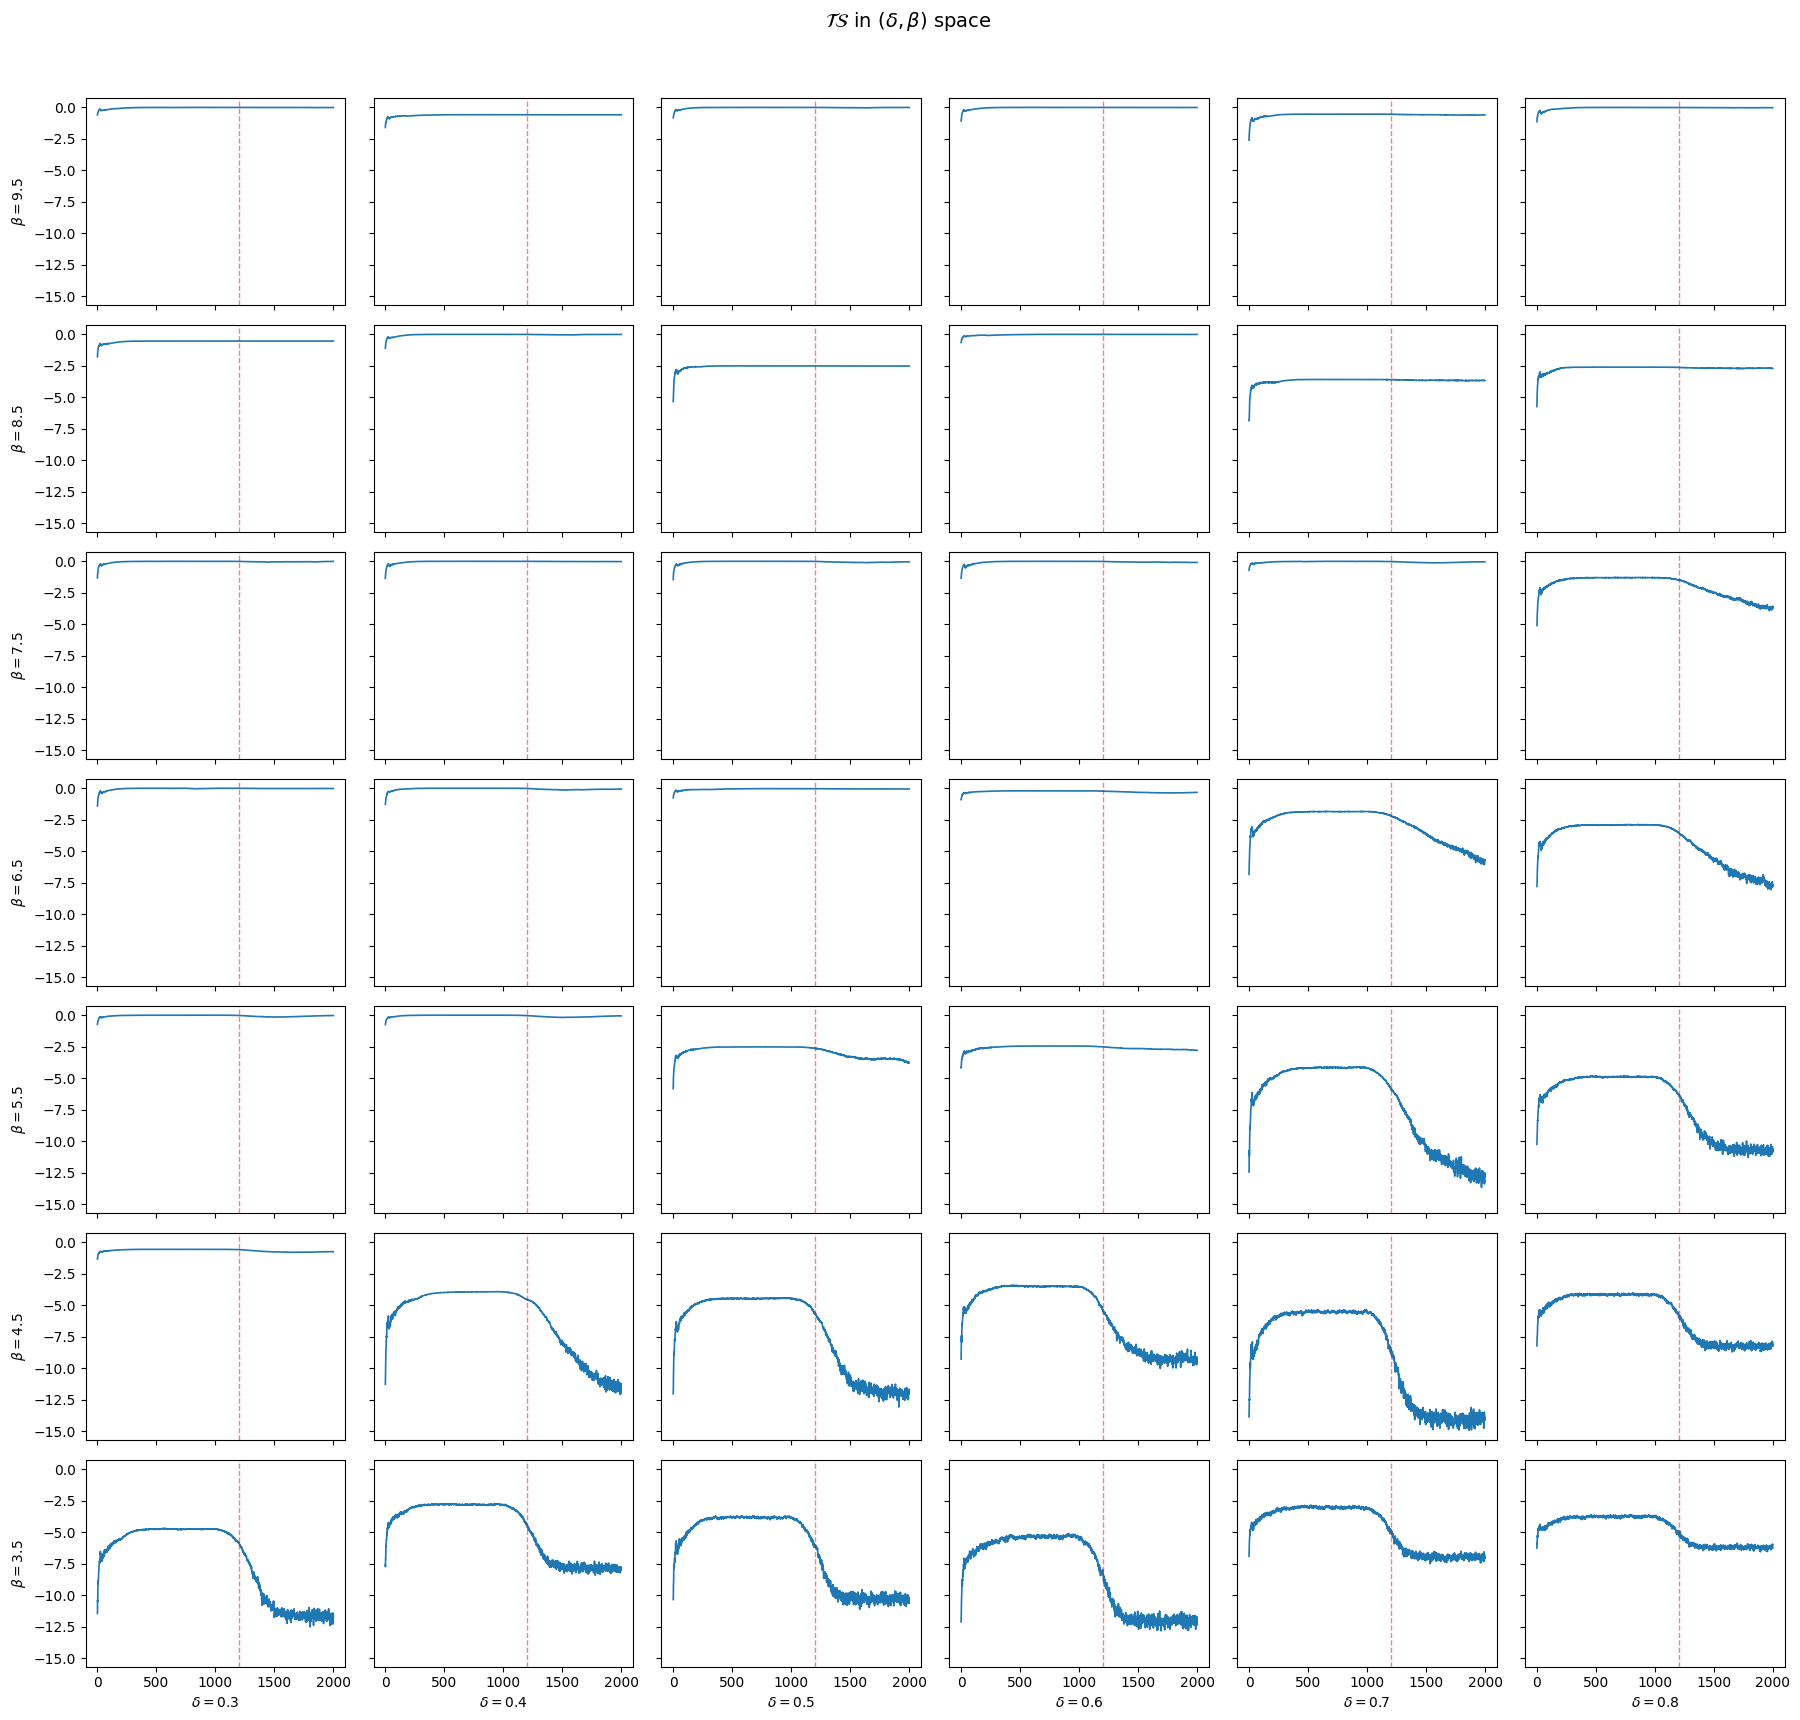

In [29]:
beta_arr = np.asarray(beta_list)
delta_arr = np.asarray(delta_list)

# Media (e deviazione standard) sulle simulazioni lungo l'asse 0 -> shape (2000, n_beta, n_delta)
n_sim = global_reward4_results.shape[0]
ts_mean = np.mean(global_reward4_results, axis=0)
ts_std = np.std(global_reward4_results, axis=0) if n_sim > 1 else None

# Indici ordinati in senso crescente per rispettare l'orientamento degli assi
beta_sorted_idx = np.argsort(beta_arr)
delta_sorted_idx = np.argsort(delta_arr)

n_beta = len(beta_arr)
n_delta = len(delta_arr)

fig, axes = plt.subplots(
    nrows=n_beta,
    ncols=n_delta,
    figsize=(3 * n_delta, 2.5 * n_beta),
    sharex=True,
    sharey=True,
    squeeze=False
)

t = np.arange(ts_mean.shape[0])

for row in range(n_beta):
    # row=0 corrisponde al beta massimo (in alto), row=n_beta-1 al beta minimo (in basso)
    b_idx = beta_sorted_idx[n_beta - 1 - row]
    beta_val = beta_arr[b_idx]

    for col in range(n_delta):
        d_idx = delta_sorted_idx[col]
        delta_val = delta_arr[d_idx]

        ax = axes[row, col]
        mean_curve = ts_mean[:, b_idx, d_idx]

        ax.plot(t, mean_curve, linewidth=1.2)
        if ts_std is not None:
            std_curve = ts_std[:, b_idx, d_idx]
            ax.fill_between(t, mean_curve - std_curve, mean_curve + std_curve, alpha=0.2)

        ax.axvline(x=tmax, color='red', linestyle='--', alpha=0.5, linewidth=1)

        # Valori dei parametri sui bordi inferiori e sinistri
        if row == n_beta - 1:
            ax.set_xlabel(rf'$\delta = {delta_val}$', fontsize=10)
        if col == 0:
            ax.set_ylabel(rf'$\beta = {beta_val}$', fontsize=10)

fig.suptitle(r'$\mathcal{TS}$ in ($\delta, \beta$) space', fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [22]:
load = True

if load:
    results = np.load(f"{saving_folder}/results_withdrawal.npz")
    op_s_results = results['op_s_results']
    op_p_results = results['op_p_results']
    global_reward4_results = results['global_reward4_results']

In [23]:
def plot_heatmap(metric, delta_list, beta_list, cmap='summer', title=None):
    """
    Genera un heatmap con estensione centrata sui pixel, tick allineati
    e etichette in formato LaTeX.
    """
    # Calcolo degli step per centrare i pixel attorno ai punti
    d_delta = (max(delta_list) - min(delta_list)) / (len(delta_list) - 1) if len(delta_list) > 1 else 0.5
    d_beta  = (max(beta_list)  - min(beta_list))  / (len(beta_list)  - 1) if len(beta_list)  > 1 else 0.5

    extent = [
        min(delta_list) - d_delta / 2,
        max(delta_list) + d_delta / 2,
        min(beta_list)  - d_beta  / 2,
        max(beta_list)  + d_beta  / 2
    ]

    plt.figure()
    plt.imshow(metric, cmap=cmap, extent=extent, origin='lower', aspect='auto')
    plt.colorbar()

    # Tick al centro dei pixel
    plt.xticks(delta_list)
    plt.yticks(beta_list)

    # Etichette in LaTeX (usa r'$\Delta$' se preferisci la lettera maiuscola)
    plt.xlabel(r'$\delta$')  
    plt.ylabel(r'$\beta$')

    if title:
        plt.title(title)

    plt.tight_layout()
    beta_crit_values = [beta_crit(d, s0) for d in delta_list]
    plt.plot(delta_list, beta_crit_values, color='red', linestyle='--', label=r'$\beta_{crit}$')
    plt.show()

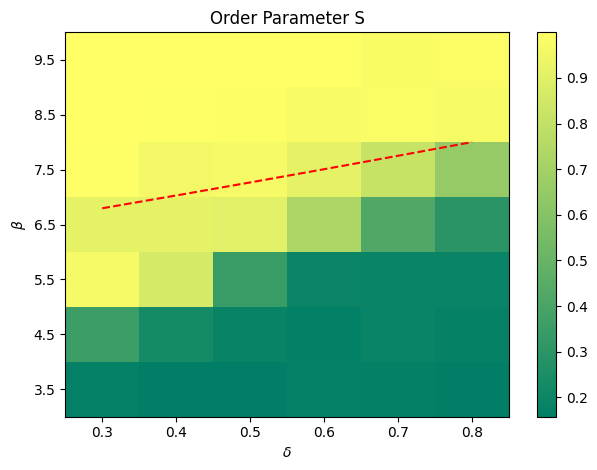

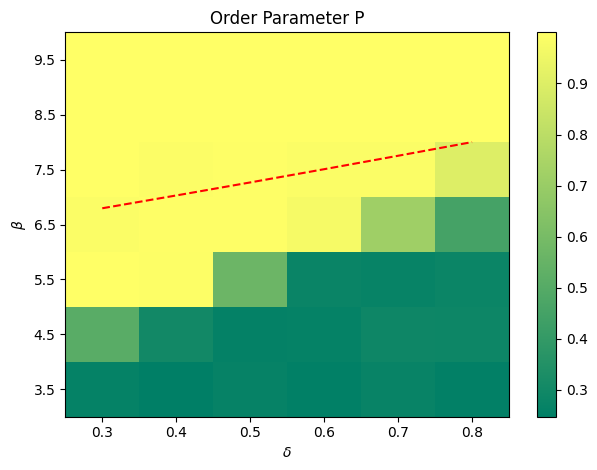

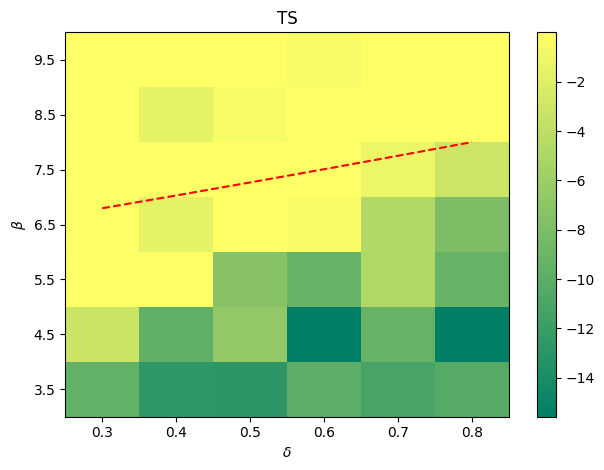

In [24]:
op_s_avg = op_s_results.mean(axis=0)
plot_heatmap(op_s_avg, delta_list, beta_list, cmap='summer', title='Order Parameter S')
op_p_avg = op_p_results.mean(axis=0)
plot_heatmap(op_p_avg, delta_list, beta_list, cmap='summer', title='Order Parameter P')
avg_global_reward4 = global_reward4_results.mean(axis=0)
plot_heatmap(avg_global_reward4, delta_list, beta_list, cmap='summer', title='TS')

In [27]:
# save the results
np.savez(f"{saving_folder}/results_withdrawal.npz",
         op_s_results=op_s_results,
         op_p_results=op_p_results,
         global_reward4_results=global_reward4_results
)